# Moosic 04: Final analysis

In this notebook I put together everything I learned in the first three notebooks and build the final playlists.

**The task:** Moosic's experts make every playlist by hand. They want to know if machine learning can help.
- Each playlist should have **50 to 250 songs**.
- The songs in a playlist should **belong together**.

With about 5,000 songs, 50 to 250 songs per playlist means between 5,000 / 250 = **20** and 5,000 / 50 = **100** playlists.

**My steps:**
1. Load and clean the data
2. Choose the features
3. Scale the features
4. PCA
5. Choose the number of playlists
6. Build the playlists
7. Check if the playlists are good
8. Save the playlists
9. My final playlists

## 1. Load and clean the data

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import PowerTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

from sklearn import set_config
set_config(transform_output='pandas')   # so scikit-learn gives back DataFrames with column names

%matplotlib inline

random_seed = 42   # I use the same seed everywhere, so I get the same playlists every time

In [34]:
raw_df = pd.read_csv('../data/3_spotify_5000_songs.csv', index_col=0)
raw_df.head()

,name,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,type,duration_ms,time_signature,id,html
0,Se Eu Quiser Falar Com Deus ...,Gilberto Gil,0.658,0.2590,11,-13.141,0,0.0705,0.694,0.000059,0.975,0.306,110.376,,256213,4,1n7JnwviZ7zf0LR1tcGFq7,https://open.spotify.com/track/1n7JnwviZ7zf0LR...
1,Saudade De Bahia ...,Antônio Carlos Jobim,0.742,0.3990,2,-12.646,1,0.0346,0.217,0.000002,0.107,0.693,125.039,,191867,4,5QGM1U0eCYrQuwSJwTm5Zq,https://open.spotify.com/track/5QGM1U0eCYrQuwS...
2,"Canta Canta, Minha Gente ...",Martinho Da Vila,0.851,0.7300,2,-11.048,1,0.3470,0.453,0.000063,0.124,0.905,93.698,,152267,4,0NLIFSZxPzQhCwnkn5PJYs,https://open.spotify.com/track/0NLIFSZxPzQhCwn...
3,Mulher Eu Sei ...,Chico César,0.705,0.0502,4,-18.115,1,0.0471,0.879,0.000041,0.386,0.524,106.802,,186227,4,3mXqOdlLE1k67WsAxryPFs,https://open.spotify.com/track/3mXqOdlLE1k67Ws...
4,Rosa Morena ...,Kurt Elling,0.651,0.1190,6,-19.807,1,0.0380,0.916,0.000343,0.104,0.402,120.941,,273680,4,7bSzjzjTkWT2CkIPPdp0eA,https://open.spotify.com/track/7bSzjzjTkWT2CkI...


Like in notebook 01, the column names and the text have extra spaces. I remove them first.

In [35]:
raw_df.columns = raw_df.columns.str.strip()

raw_df['name'] = raw_df['name'].str.strip()
raw_df['artist'] = raw_df['artist'].str.strip()
raw_df['type'] = raw_df['type'].str.strip()
raw_df['id'] = raw_df['id'].str.strip()

print('Songs in the file:', len(raw_df))

Songs in the file: 5235


Now I check for the problems I found in the earlier notebooks.

In [36]:
print('Same Spotify id twice:', raw_df['id'].duplicated().sum())
print('Same name and artist twice:', raw_df.duplicated(subset=['name', 'artist']).sum())
print('Songs with tempo 0:', (raw_df['tempo'] == 0).sum())

Same Spotify id twice: 64
Same name and artist twice: 121
Songs with tempo 0: 1


In [37]:
# The song with tempo 0: all its values are 0, so it's missing data
raw_df[raw_df['tempo'] == 0]

,name,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,type,duration_ms,time_signature,id,html
629,Shake It Off,Taylor Swift,0.0,0.0,0,-60.0,0,0.0,0.0,0.0,0.0,0.0,0.0,,219000,0,4461iENdKgtUYpveYwIarD,https://open.spotify.com/track/4461iENdKgtUYpv...


In [38]:
songs_df = raw_df.drop_duplicates(subset='id')                     # same song id twice
songs_df = songs_df.drop_duplicates(subset=['name', 'artist'])     # same song uploaded twice with a new id
songs_df = songs_df[songs_df['tempo'] > 0]                         # the broken row
songs_df = songs_df.drop(columns=['type', 'id', 'html'])           # empty column and text columns
songs_df = songs_df.set_index(['name', 'artist'])                  # so I can always see which song a row is

print('Songs after cleaning:', len(songs_df))

Songs after cleaning: 5113


## 2. Choose the features

In notebook 01 I saw that some columns are not useful for making playlists:
- `key` and `mode` are labels, not amounts. Key 11 is not "more" than key 1.
- `time_signature` is almost always 4, so it can't tell songs apart.
- `duration_ms` is the length of a song. It says nothing about how a song sounds, and without scaling it decided almost everything.

So I keep these 9 features:

In [39]:
audio_features = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
                  'instrumentalness', 'liveness', 'valence', 'tempo']

features_df = songs_df[audio_features]
features_df.describe().round(2)

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
count,5113.00,5113.00,5113.00,5113.00,5113.00,5113.00,5113.00,5113.00,5113.00
mean,0.51,0.65,-9.38,0.08,0.29,0.26,0.19,0.44,118.66
std,0.22,0.29,6.28,0.07,0.36,0.37,0.15,0.28,28.59
min,0.06,0.00,-44.41,0.02,0.00,0.00,0.01,0.02,34.86
25%,0.30,0.48,-11.39,0.04,0.00,0.00,0.09,0.20,96.06
50%,0.53,0.74,-7.37,0.06,0.10,0.00,0.12,0.41,118.99
75%,0.68,0.90,-5.32,0.10,0.57,0.66,0.24,0.67,134.10
max,0.97,1.00,1.34,0.92,1.00,0.98,0.99,0.98,213.99


In [40]:
# Quick check: time_signature really is almost always 4
songs_df['time_signature'].value_counts(normalize=True).round(3)

time_signature
4    0.895
3    0.081
5    0.013
1    0.010
Name: proportion, dtype: float64

## 3. Scale the features

In notebook 01 I compared 5 scalers. I chose **PowerTransformer** because:
- every feature gets the same "say" in the distance between songs,
- it pulls in long tails (like speechiness and liveness), so a few extreme songs don't stretch everything,
- in notebook 02 it got closer to the 50 to 250 songs rule than MinMax.

In [41]:
my_power = PowerTransformer()
scaled_df = my_power.fit_transform(features_df)
scaled_df.head()

,,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
name,artist,,,,,,,,,
Se Eu Quiser Falar Com Deus,Gilberto Gil,0.688660,-1.361222,-0.862465,0.206533,1.277150,-0.781932,2.074386,-0.409958,-0.209010
Saudade De Bahia,Antônio Carlos Jobim,1.086078,-1.033237,-0.796241,-1.042393,0.233410,-0.782462,-0.505131,0.931087,0.307062
"Canta Canta, Minha Gente",Martinho Da Vila,1.608326,0.099601,-0.564003,1.974728,0.906940,-0.781888,-0.256208,1.536379,-0.861172
Mulher Eu Sei,Chico César,0.910472,-1.716228,-1.418797,-0.526809,1.452406,-0.782102,1.522543,0.389273,-0.342356
Rosa Morena,Kurt Elling,0.655747,-1.615271,-1.574127,-0.892008,1.480181,-0.779282,-0.552098,-0.042144,0.167506


In [42]:
# Check: now every feature has a similar spread (variance close to 1)
scaled_df.var().round(2)

danceability        1.0
energy              1.0
loudness            1.0
speechiness         1.0
acousticness        1.0
instrumentalness    1.0
liveness            1.0
valence             1.0
tempo               1.0
dtype: float64

## 4. PCA

In notebook 03 I learned that keeping 95% of the information needs 7 of the 9 components,
and that with PCA the 50 to 250 songs rule works for more numbers of playlists.

I also learned a trap: with only 3 components the silhouette score looked much better, but on the original
features it was much worse. So I keep 95% and not fewer.

In [43]:
my_pca = PCA(n_components=0.95)      # keep as many components as needed for 95% of the information
pca_df = my_pca.fit_transform(scaled_df)

print('Number of components:', my_pca.n_components_)
print('Information kept:', round(my_pca.explained_variance_ratio_.sum() * 100, 1), '%')

Number of components: 7
Information kept: 95.3 %


## 5. Choose the number of playlists

I try every k from 20 to 100. For each k I save:
- the **inertia** (for the elbow method),
- the **silhouette score**,
- the **smallest and biggest playlist**,
- the **% of songs in a playlist with 50 to 250 songs** (the business rule).

This cell takes about a minute.

In [44]:
results = []

for k in range(20, 101):
    kmeans = KMeans(n_clusters=k, random_state=random_seed, n_init='auto')
    kmeans.fit(pca_df)

    sizes = np.bincount(kmeans.labels_)                      # number of songs in each playlist
    good_size = (sizes >= 50) & (sizes <= 250)               # True for playlists that follow the rule
    songs_ok = sizes[good_size].sum() / len(pca_df) * 100     # % of songs in a good playlist

    results.append({'k': k,
                    'inertia': kmeans.inertia_,
                    'silhouette': silhouette_score(pca_df, kmeans.labels_),
                    'smallest': sizes.min(),
                    'biggest': sizes.max(),
                    'songs in valid playlists (%)': songs_ok})

k_results = pd.DataFrame(results)
k_results.head()

,k,inertia,silhouette,smallest,biggest,songs in valid playlists (%)
0,20,11706.361324,0.182111,131,412,43.262273
1,21,11541.884350,0.179142,131,367,42.069235
2,22,11354.579622,0.175006,130,330,54.038725
3,23,11049.309986,0.176949,128,320,59.162918
4,24,10959.637486,0.174056,132,300,72.345003


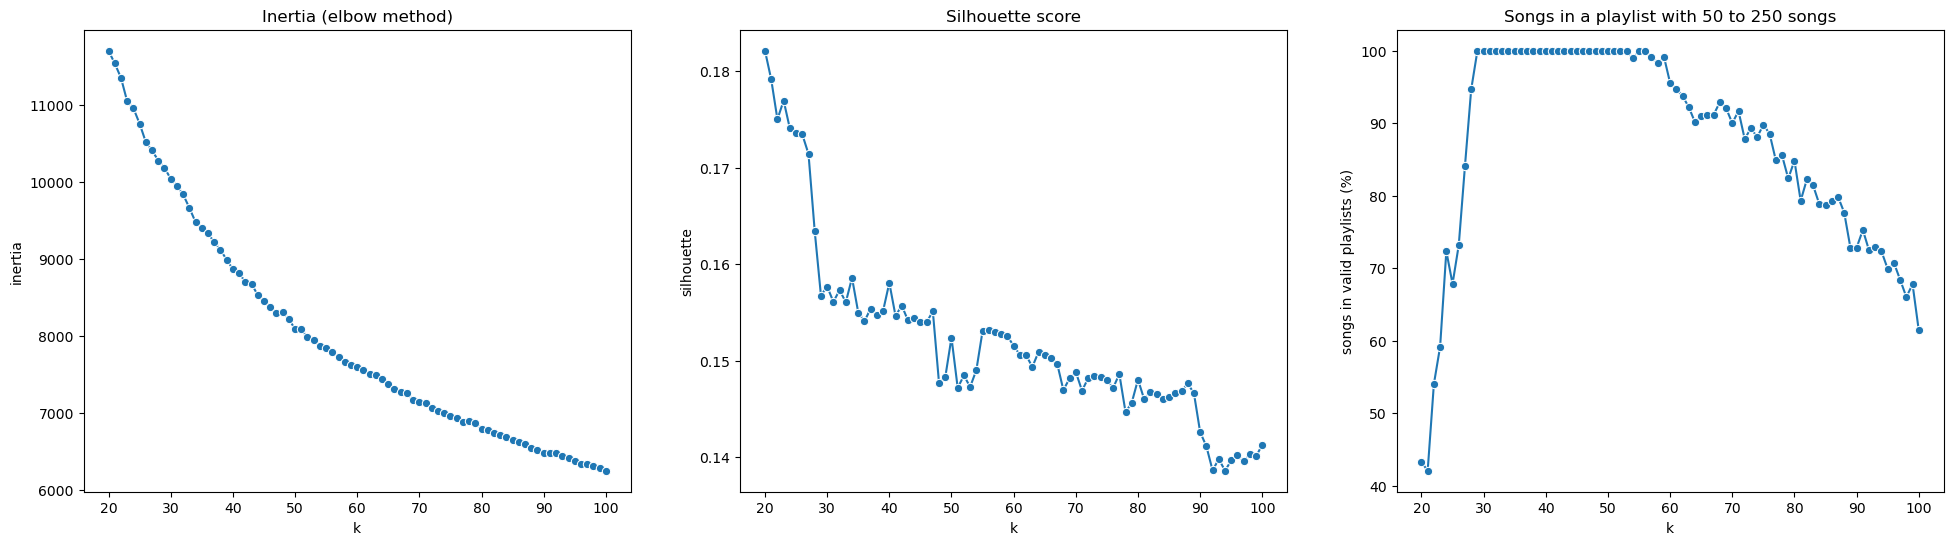

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(24, 6))

sns.lineplot(data=k_results, x='k', y='inertia', marker='o', ax=axes[0])
axes[0].set_title('Inertia (elbow method)')

sns.lineplot(data=k_results, x='k', y='silhouette', marker='o', ax=axes[1])
axes[1].set_title('Silhouette score')

sns.lineplot(data=k_results, x='k', y='songs in valid playlists (%)', marker='o', ax=axes[2])
axes[2].set_title('Songs in a playlist with 50 to 250 songs')

plt.show()

What I see:
- **Inertia:** it goes down slowly. I can't find a clear elbow.
- **Silhouette:** it stays low (around 0.15). Music doesn't come in clearly separate groups.
- **Business rule:** only some values of k put *every* song in a playlist of the right size.

So the elbow and the silhouette alone can't decide. I let the business rule decide first, and then I use the silhouette score to choose between the k that are left.

In [46]:
# Only the k where 100% of the songs are in a playlist with 50 to 250 songs
valid_k = k_results[k_results['songs in valid playlists (%)'] == 100]
valid_k.round(3)

,k,inertia,silhouette,smallest,biggest,songs in valid playlists (%)
9,29,10186.573,0.157,106,246,100.0
10,30,10041.186,0.158,76,240,100.0
11,31,9954.258,0.156,96,248,100.0
12,32,9837.920,0.157,78,232,100.0
13,33,9664.754,0.156,82,217,100.0
14,34,9478.502,0.159,72,223,100.0
15,35,9408.249,0.155,70,202,100.0
16,36,9334.536,0.154,75,215,100.0
17,37,9216.391,0.155,68,212,100.0
18,38,9117.653,0.155,67,202,100.0


In [47]:
# From these, the one with the highest silhouette score
best_row = valid_k.sort_values('silhouette', ascending=False).iloc[0]
chosen_k = int(best_row['k'])
print('Number of playlists:', chosen_k)

Number of playlists: 34


## 6. Build the playlists

In [48]:
final_kmeans = KMeans(n_clusters=chosen_k, random_state=random_seed, n_init='auto')
final_kmeans.fit(pca_df)

# I add the playlist number to the original (unscaled) data, because those numbers are easier to read
playlists_df = songs_df.copy()
playlists_df['playlist'] = final_kmeans.labels_.astype(int)

playlists_df[['playlist']].head(10)

,,playlist
name,artist,
Se Eu Quiser Falar Com Deus,Gilberto Gil,31
Saudade De Bahia,Antônio Carlos Jobim,29
"Canta Canta, Minha Gente",Martinho Da Vila,17
Mulher Eu Sei,Chico César,31
Rosa Morena,Kurt Elling,7
Desafinado,Stan Getz,30
Madalena,Maria Gasolina,27
O Meu Amor É Glòria,Sílvia Pérez Cruz,16
Brigas Nunca Mais,Paula Morelenbaum,29


In [49]:
# How many songs in each playlist?
playlist_sizes = playlists_df['playlist'].value_counts().sort_index()
playlist_sizes

playlist
0     131
1     217
2     148
3     126
4     194
5     176
6     161
7     180
8     100
9     192
10    165
11    183
12     86
13    132
14    201
15     97
16    159
17    144
18    153
19    163
20    187
21    148
22    127
23    223
24    202
25    136
26     72
27     94
28    203
29    164
30     93
31     81
32    164
33    111
Name: count, dtype: int64

### Giving each playlist a description

A playlist number like "23" doesn't mean anything to a listener. For each playlist, I compare its average
with the average of all songs. If a feature is much higher or lower than normal (more than 0.75 standard deviations),
I use it in the description. I take at most the 3 strongest ones.

In [50]:
# Words for each feature: (if it's high, if it's low)
plain_words = {
    'danceability': ('danceable', 'not danceable'),
    'energy': ('energetic', 'calm'),
    'loudness': ('loud', 'quiet'),
    'speechiness': ('spoken / rap', 'no spoken words'),
    'acousticness': ('acoustic', 'electronic'),
    'instrumentalness': ('instrumental', 'with vocals'),
    'liveness': ('live feel', 'studio feel'),
    'valence': ('happy', 'dark'),
    'tempo': ('fast', 'slow'),
}

# Average of each feature, per playlist
playlist_means = playlists_df.groupby('playlist')[audio_features].mean()

# How far each playlist is from the average song, in standard deviations
difference = (playlist_means - features_df.mean()) / features_df.std()
difference.round(2).head()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
playlist,,,,,,,,,
0,-1.08,-1.83,-2.14,-0.54,1.79,1.56,-0.28,-1.01,1.19
1,0.81,0.59,0.68,-0.51,-0.60,-0.69,1.08,0.93,-0.02
2,-0.93,0.97,0.49,0.61,-0.80,-0.60,1.00,-0.85,-0.02
3,-1.29,0.95,0.26,0.33,-0.79,1.26,0.84,-0.78,1.29
4,1.20,0.42,0.72,1.37,-0.47,-0.70,-0.63,0.79,-0.44


In [51]:
descriptions = {}

for p in difference.index:
    row = difference.loc[p]
    strong = row[row.abs() > 0.75]                                  # only the features that stand out
    strong = strong.sort_values(key=abs, ascending=False).head(3)   # the 3 strongest

    words = []
    for feature, value in strong.items():
        if value > 0:
            words.append(plain_words[feature][0])   # high
        else:
            words.append(plain_words[feature][1])   # low

    if len(words) == 0:
        descriptions[p] = 'All-round mix'
    else:
        descriptions[p] = ', '.join(words).capitalize()

descriptions[28]

'Quiet, calm, acoustic'

In [52]:
# The 3 artists with the most songs in each playlist
top_artists = {}
for p in playlist_sizes.index:
    artists = playlists_df[playlists_df['playlist'] == p].index.get_level_values('artist')
    top_artists[p] = ', '.join(pd.Series(artists).value_counts().head(3).index)

summary_df = pd.DataFrame({'songs': playlist_sizes,
                           'description': pd.Series(descriptions),
                           'top artists': pd.Series(top_artists)})
summary_df.index.name = 'playlist'
summary_df

,songs,description,top artists
playlist,,,
0,131,"Quiet, calm, acoustic","Henry Smith, Johann Sebastian Bach, Flying Fin..."
1,217,"Live feel, happy, danceable","Katy Perry, Spice Girls, David Guetta"
2,148,"Live feel, energetic, not danceable","Morbid Angel, Morgoth, Obituary"
3,126,"Fast, not danceable, instrumental","Entombed, Asphyx, Avulsed"
4,194,"Spoken / rap, danceable, happy","50 Cent, Dr. Dre, Usher"
5,176,"Instrumental, not danceable, electronic","Broken Hope, Carcass, Suffocation"
6,161,All-round mix,"Tokio Hotel, The Script, Vanessa Carlton"
7,180,"Acoustic, calm, slow","Simon & Garfunkel, Dionne Warwick, Angel Olsen"
8,100,Instrumental,"Da Souza, deadmau5, The Jesus and Mary Chain"


### Check 1: does every playlist have 50 to 250 songs?

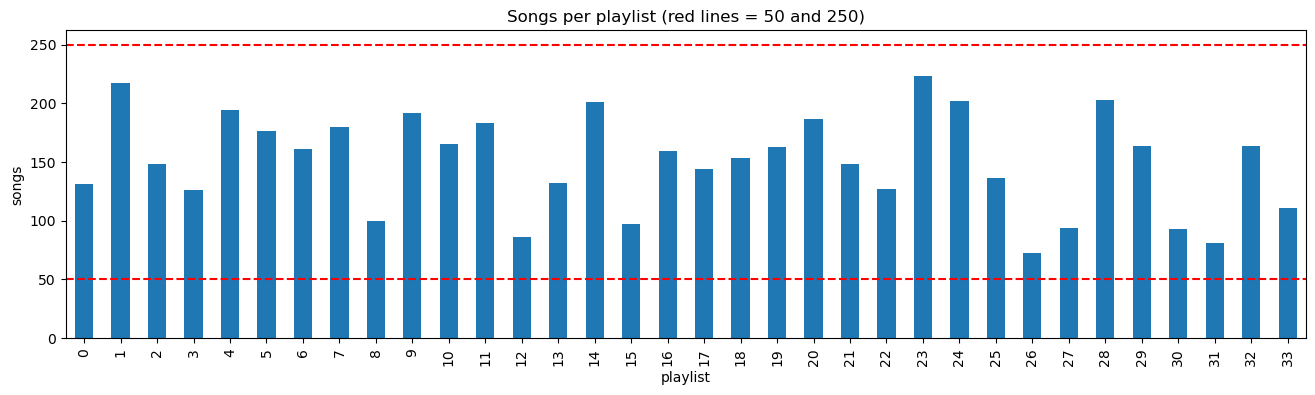

Smallest playlist: 72 songs
Biggest playlist: 223 songs
All playlists between 50 and 250: True


In [53]:
fig, ax = plt.subplots(figsize=(16, 4))
playlist_sizes.plot.bar(ax=ax)
ax.axhline(50, color='red', linestyle='--')
ax.axhline(250, color='red', linestyle='--')
ax.set_title('Songs per playlist (red lines = 50 and 250)')
ax.set_xlabel('playlist')
ax.set_ylabel('songs')
plt.show()

print('Smallest playlist:', playlist_sizes.min(), 'songs')
print('Biggest playlist:', playlist_sizes.max(), 'songs')
print('All playlists between 50 and 250:', playlist_sizes.between(50, 250).all())

## 8. Save the playlists

I save two files:
- `results/moosic_playlists.csv`: one row per song (I use it in notebook 05 to post the playlists to Spotify)
- `results/moosic_playlist_summary.csv`: one row per playlist

In [56]:
# Add the description to every song too, so each song shows the name of its playlist
playlists_df['description'] = playlists_df['playlist'].map(summary_df['description'])

playlists_df[['playlist', 'description']].head(10)


,,playlist,description
name,artist,,
Se Eu Quiser Falar Com Deus,Gilberto Gil,31,"Live feel, acoustic, calm"
Saudade De Bahia,Antônio Carlos Jobim,29,"Happy, acoustic"
"Canta Canta, Minha Gente",Martinho Da Vila,17,"Spoken / rap, danceable, slow"
Mulher Eu Sei,Chico César,31,"Live feel, acoustic, calm"
Rosa Morena,Kurt Elling,7,"Acoustic, calm, slow"
Desafinado,Stan Getz,30,"Calm, fast, acoustic"
Madalena,Maria Gasolina,27,"Acoustic, calm, instrumental"
O Meu Amor É Glòria,Sílvia Pérez Cruz,16,"Spoken / rap, live feel, danceable"
Brigas Nunca Mais,Paula Morelenbaum,29,"Happy, acoustic"


In [57]:
playlists_df.to_csv('../results/moosic_playlists.csv')
summary_df.round(3).to_csv('../results/moosic_playlist_summary.csv')


## 9. My final playlists

All 34 playlists with their description, number of songs and top artists.

In [58]:
pd.set_option('display.max_rows', 50)
summary_df[['description', 'songs', 'top artists']]

,description,songs,top artists
playlist,,,
0,"Quiet, calm, acoustic",131,"Henry Smith, Johann Sebastian Bach, Flying Fin..."
1,"Live feel, happy, danceable",217,"Katy Perry, Spice Girls, David Guetta"
2,"Live feel, energetic, not danceable",148,"Morbid Angel, Morgoth, Obituary"
3,"Fast, not danceable, instrumental",126,"Entombed, Asphyx, Avulsed"
4,"Spoken / rap, danceable, happy",194,"50 Cent, Dr. Dre, Usher"
5,"Instrumental, not danceable, electronic",176,"Broken Hope, Carcass, Suffocation"
6,All-round mix,161,"Tokio Hotel, The Script, Vanessa Carlton"
7,"Acoustic, calm, slow",180,"Simon & Garfunkel, Dionne Warwick, Angel Olsen"
8,Instrumental,100,"Da Souza, deadmau5, The Jesus and Mary Chain"
